# 03 · Training the agent

PPO with action masking and a graph network over the board, trained through a curriculum (random/greedy → weaker strategies → all tuned strategies) and then a self-play league with prioritised fictitious self-play.

Data: `results/training/*.jsonl`, copied from `runs/<name>/metrics.jsonl` (`python -m catanbot.train --config configs/main.yaml`, then `configs/phase2.yaml` for the second phase).

## Architecture matters: flat MLP vs. graph network
Same config, same seeds, same curriculum; only the policy network differs. The graph network scores every intersection, road and tile with a network *shared* across the board, so lessons about one spot transfer to all of them.

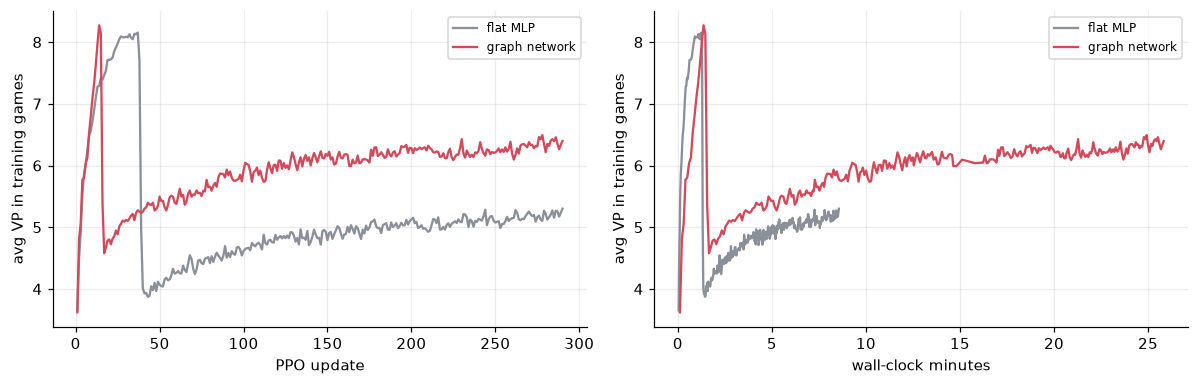

In [1]:
import json
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"balanced": "#2a6f97", "ows": "#7d5ba6", "road_builder": "#b5532f", "dev_rush": "#3c8d5a",
          "port_master": "#c9962b", "greedy": "#8a8f98", "random": "#b8bcc4", "learned": "#d1495b"}
LABELS = {"balanced": "Balanced", "ows": "Ore-Wheat-Sheep", "road_builder": "Road Builder",
          "dev_rush": "Dev-Card Rush", "port_master": "Port Master", "learned": "Learned (RL)"}

def load(p):
    d = {}
    for l in Path(p).read_text().splitlines():
        r = json.loads(l); d[r['update']] = r
    return pl.DataFrame([d[k] for k in sorted(d)], infer_schema_length=None)
mlp = load(RESULTS / 'training' / 'mlp_baseline_metrics.jsonl')
graph = load(RESULTS / 'training' / 'main_metrics.jsonl')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, d, c in [('flat MLP', mlp, '#8a8f98'), ('graph network', graph, '#d1495b')]:
    d = d.filter(pl.col('update') <= mlp['update'].max())
    axes[0].plot(d['update'], d['avg_vp'], label=name, color=c)
    axes[1].plot(d['elapsed_s'] / 60, d['avg_vp'], label=name, color=c)
axes[0].set_xlabel('PPO update'); axes[1].set_xlabel('wall-clock minutes')
for ax in axes: ax.set_ylabel('avg VP in training games'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [2]:
lines = [json.loads(l) for l in (RESULTS / 'training' / 'main_metrics.jsonl').read_text().splitlines()]
m = {r['update']: r for r in lines}
m = pl.DataFrame([m[k] for k in sorted(m)], infer_schema_length=None)
print(f"{m['update'].max()} updates, {m['decisions'].max():,} decisions, {m['games'].max():,} games, "
      f"{m['elapsed_s'].max() / 3600:.1f} h")

8000 updates, 262,144,000 decisions, 2,581,972 games, 16.3 h


## Evaluation win rate
Every 50 updates the current policy (argmax actions) plays fixed tables on the same seeds.

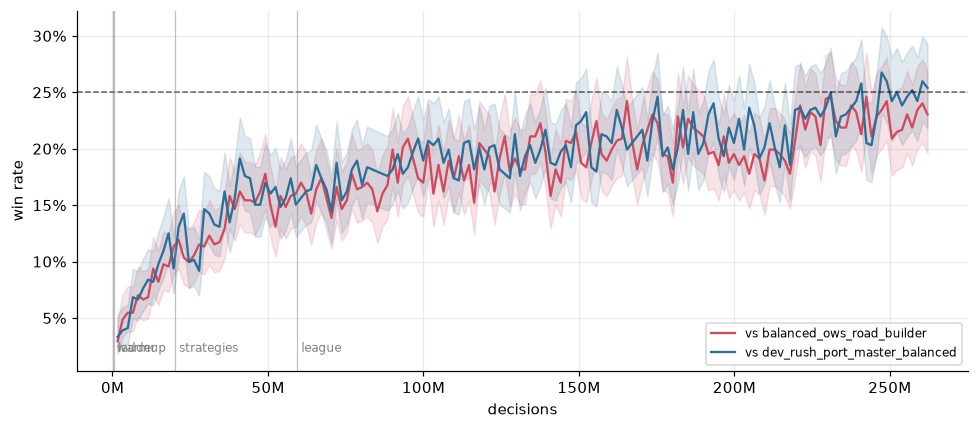

In [3]:
ev_cols = [c for c in m.columns if c.startswith('eval/') and c.endswith('/win_rate')]
fig, ax = plt.subplots(figsize=(9, 4))
for c, color in zip(ev_cols, ['#d1495b', '#2a6f97', '#3c8d5a']):
    tag = c.split('/')[1]
    e = m.filter(pl.col(c).is_not_null())
    ax.fill_between(e['decisions'], e[f'eval/{tag}/ci_low'], e[f'eval/{tag}/ci_high'], color=color, alpha=0.15)
    ax.plot(e['decisions'], e[c], color=color, label=f'vs {tag}')
ax.axhline(0.25, color='k', ls='--', lw=1, alpha=0.6)
stages = m.select(['decisions', 'stage'])
prev = None
for d, st in stages.iter_rows():
    if st != prev:
        ax.axvline(d, color='grey', lw=0.8, alpha=0.5); ax.text(d, 0.02, f' {st}', fontsize=8, color='grey')
        prev = st
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.xaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}M')
ax.set_xlabel('decisions'); ax.set_ylabel('win rate'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Optimisation diagnostics

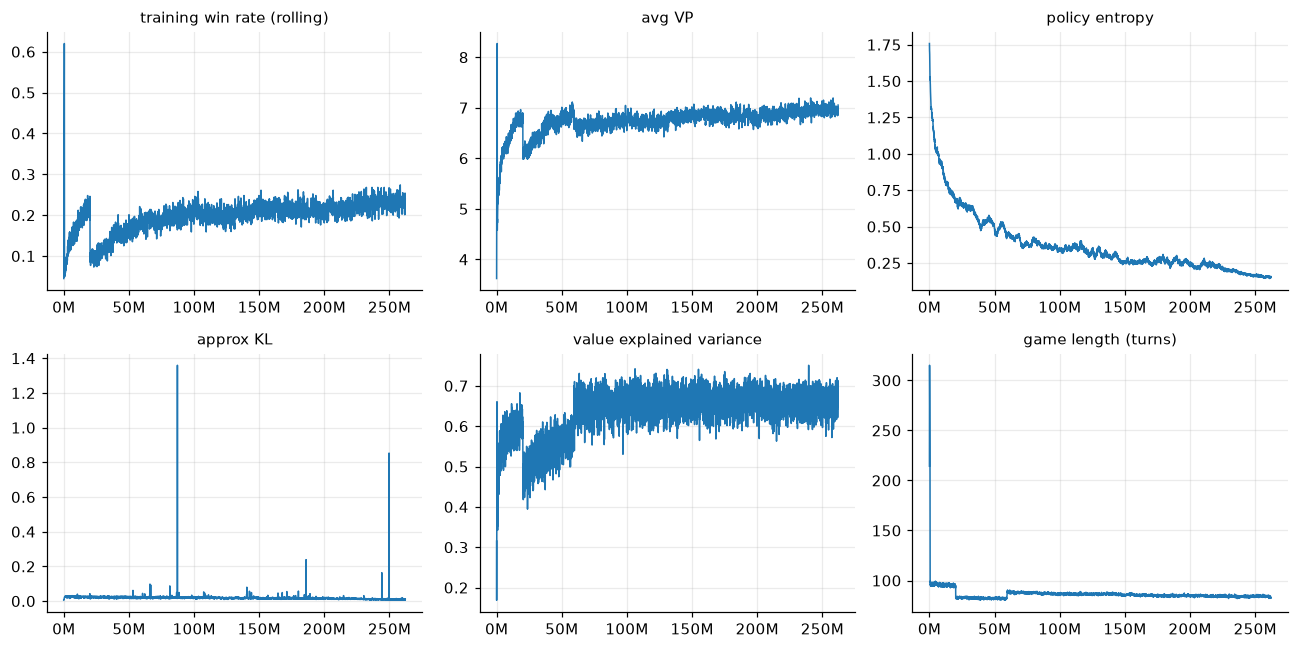

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, title) in zip(axes.flat, [('win_rate', 'training win rate (rolling)'), ('avg_vp', 'avg VP'),
        ('entropy', 'policy entropy'), ('approx_kl', 'approx KL'), ('explained_var', 'value explained variance'),
        ('avg_turns', 'game length (turns)')]):
    ax.plot(m['decisions'], m[col], lw=1)
    ax.set_title(title, fontsize=10); ax.xaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}M')
plt.tight_layout(); plt.show()

## Who the league thinks is hardest
PFSP beat-rates: how often the agent finishes ahead of each opponent (EMA). Opponents with low beat-rates are sampled more.

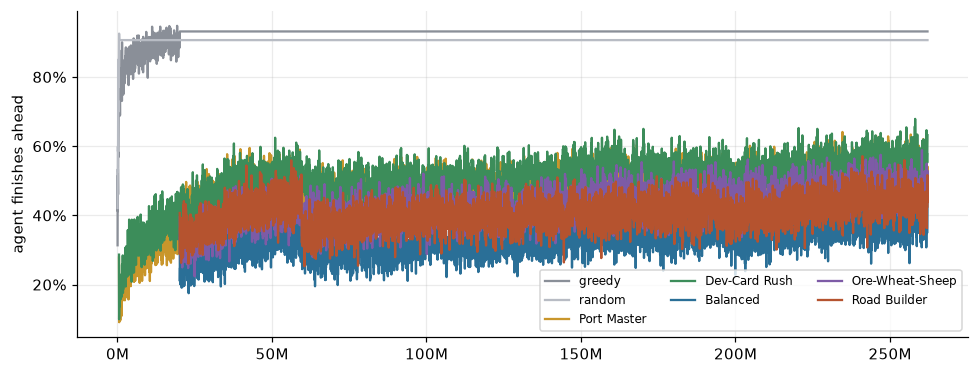

In [5]:
beat = [c for c in m.columns if c.startswith('beat/bot')]
fig, ax = plt.subplots(figsize=(9, 3.5))
for c in beat:
    b = c.split('_', 1)[1]
    e = m.filter(pl.col(c).is_not_null())
    ax.plot(e['decisions'], e[c], label=LABELS.get(b, b), color=COLORS.get(b))
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.xaxis.set_major_formatter(lambda v, _: f'{v/1e6:.0f}M')
ax.legend(fontsize=8, ncol=3); ax.set_ylabel('agent finishes ahead'); plt.tight_layout(); plt.show()

## Phase 2: practising against the bots it loses to
In the first run's league, half of the opponent seats went to frozen copies of the agent and to the agent itself, and the
pairwise scores above show it was already ahead of those. Phase 2 (`configs/phase2.yaml`) continues from the final weights
for 3,000 more updates with 75% of opponent seats given to strategy bots (still picked by PFSP, so the ones it beats least
come up most), a 4x larger batch (65,536 decisions per update), a lower learning rate (1e-4 to 2e-5) and no reward shaping.
Its evaluations use 2,048 games instead of 512, so the curve is less noisy.

phase 2: 3000 updates, 196,608,000 decisions, 2,055,527 games, 8.0 h


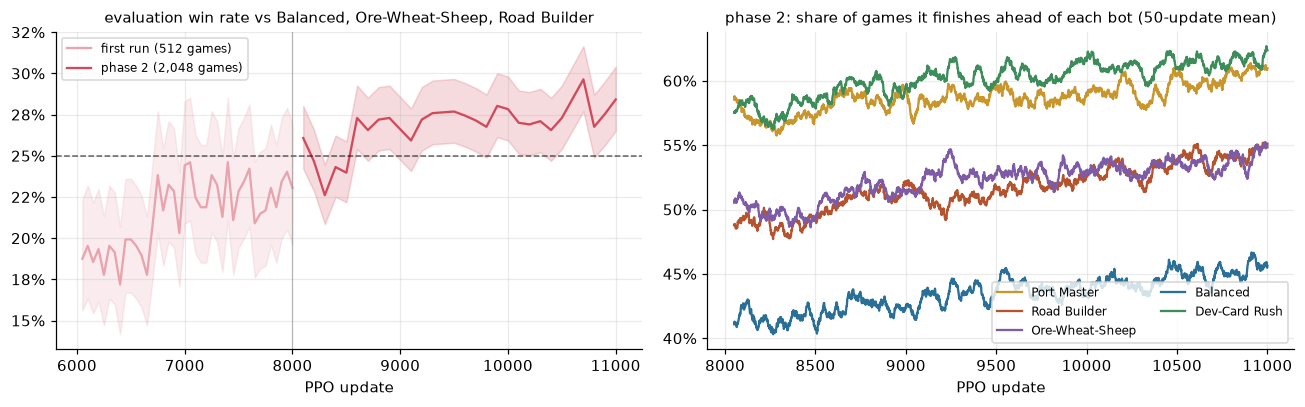

In [6]:
p2 = load(RESULTS / 'training' / 'phase2_metrics.jsonl')
start = m['update'].max()
print(f"phase 2: {p2['update'].max()} updates, {p2['decisions'].max():,} decisions, {p2['games'].max():,} games, "
      f"{p2['elapsed_s'].max() / 3600:.1f} h")
tag = 'balanced_ows_road_builder'
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for d, off, name, color in [(m.filter(pl.col('update') > start - 2000), 0, 'first run (512 games)', '#e8a3ad'),
                            (p2, start, 'phase 2 (2,048 games)', '#d1495b')]:
    e = d.filter(pl.col(f'eval/{tag}/win_rate').is_not_null())
    ax.fill_between(e['update'] + off, e[f'eval/{tag}/ci_low'], e[f'eval/{tag}/ci_high'], color=color, alpha=0.2)
    ax.plot(e['update'] + off, e[f'eval/{tag}/win_rate'], color=color, label=name)
ax.axhline(0.25, color='k', ls='--', lw=1, alpha=0.6); ax.axvline(start, color='grey', lw=0.8, alpha=0.5)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_xlabel('PPO update'); ax.legend(fontsize=8)
ax.set_title('evaluation win rate vs Balanced, Ore-Wheat-Sheep, Road Builder', fontsize=10)
ax = axes[1]
for c in [c for c in p2.columns if c.startswith('beat/bot')]:
    b = c.split('_', 1)[1]
    e = p2.filter(pl.col(c).is_not_null())
    ax.plot(e['update'] + start, e[c].rolling_mean(50), label=LABELS.get(b, b), color=COLORS.get(b))
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_xlabel('PPO update'); ax.legend(fontsize=8, ncol=2)
ax.set_title('phase 2: share of games it finishes ahead of each bot (50-update mean)', fontsize=10)
plt.tight_layout(); plt.show()